<center><h1>Magdum_Seona_HW6</h1></center>

Name: Seona Magdum
<br>
Github Username: seo2003
<br>
USC ID: 6077378254

## 1. Tree-Based Methods

Import packages

In [20]:
from IPython.display import HTML, display

display(HTML("""
<style>
    .jp-Notebook {
        font-size: 10px !important;
    }
    .jp-CodeCell .cm-editor {
        font-size: 10px !important;
    }
    .jp-OutputArea {
        font-size: 10px !important;
    }
</style>
"""))

In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import (
    confusion_matrix, accuracy_score, roc_curve, roc_auc_score,
    log_loss, recall_score, precision_score, f1_score
)

from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline


### (a) Download the APS Failure data

In [22]:
train_data = pd.read_csv("../data/aps_failure_training_set.csv",
                         skiprows=20, na_values="na")
test_data = pd.read_csv("../data/aps_failure_test_set.csv",
                        skiprows=20, na_values="na")
train_data.head()

,class,aa_000,ab_000,ac_000,ad_000,ae_000,af_000,ag_000,ag_001,ag_002,...,ee_002,ee_003,ee_004,ee_005,ee_006,ee_007,ee_008,ee_009,ef_000,eg_000
0,neg,76698,NaN,2.130706e+09,280.0,0.0,0.0,0.0,0.0,0.0,...,1240520.0,493384.0,721044.0,469792.0,339156.0,157956.0,73224.0,0.0,0.0,0.0
1,neg,33058,NaN,0.000000e+00,NaN,0.0,0.0,0.0,0.0,0.0,...,421400.0,178064.0,293306.0,245416.0,133654.0,81140.0,97576.0,1500.0,0.0,0.0
2,neg,41040,NaN,2.280000e+02,100.0,0.0,0.0,0.0,0.0,0.0,...,277378.0,159812.0,423992.0,409564.0,320746.0,158022.0,95128.0,514.0,0.0,0.0
3,neg,12,0.0,7.000000e+01,66.0,0.0,10.0,0.0,0.0,0.0,...,240.0,46.0,58.0,44.0,10.0,0.0,0.0,0.0,4.0,32.0
4,neg,60874,NaN,1.368000e+03,458.0,0.0,0.0,0.0,0.0,0.0,...,622012.0,229790.0,405298.0,347188.0,286954.0,311560.0,433954.0,1218.0,0.0,0.0


### (b) Data Preparation

#### (i) Research what types of techniques are usually used

Common techniques that are used for dealing with data with missing values include mean imputation, mode imputation and median imputation. These techniques replace the missing values with the mean, mode and median values of the column, respectively. For this assignment, I will use median impuation since the dataset contains numerical values may include outliers, making it a better representation of the data.

In [23]:
#Separate features and target variable
X_train = train_data.drop(columns=["class"])
y_train = train_data["class"]
X_test = test_data.drop(columns=["class"])
y_test = test_data["class"]
#median imputation
imputer = SimpleImputer(strategy="median")
X_train_imputed = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)
X_test_imputed = pd.DataFrame(
    imputer.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)
print("Missing values after imputation in train:", X_train_imputed.isna().sum().sum())
print("Missing values in test data:", X_test_imputed.isna().sum().sum())
print(train_data.shape)
print(test_data.shape)

Missing values after imputation in train: 0
Missing values in test data: 0
(60000, 171)
(16000, 171)


#### (ii) Calculate the coefficient of variation

In [24]:
#coefficient of variation for each feature
cv = X_train_imputed.std() / X_train_imputed.mean()
cv

aa_000      2.450938
ab_000     10.383494
ac_000      2.310241
ad_000    244.322816
ae_000     24.200137
             ...    
ee_007      5.012754
ee_008      3.259079
ee_009      5.691612
ef_000     49.366659
eg_000     42.481747
Length: 170, dtype: float64

#### (iii) Plot a correlation matrix

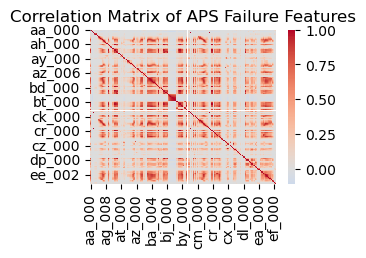

In [25]:
correlation_matrix = X_train_imputed.corr()
plt.figure(figsize=(3, 2))
sns.heatmap(correlation_matrix, cmap="coolwarm", center=0)
plt.title("Correlation Matrix of APS Failure Features")
plt.show()

#### (iv) Make scatter plots and box plots

In [26]:
#number of features to select
num_features = int(np.ceil(np.sqrt(170)))
#highest CV
top_features = cv.sort_values(ascending=False).head(num_features).index.tolist()
print("number of selected features:", len(top_features))
print(top_features)

number of selected features: 14
['cf_000', 'co_000', 'ad_000', 'cs_009', 'dh_000', 'dj_000', 'ag_000', 'as_000', 'ay_009', 'ak_000', 'az_009', 'ch_000', 'au_000', 'cr_000']


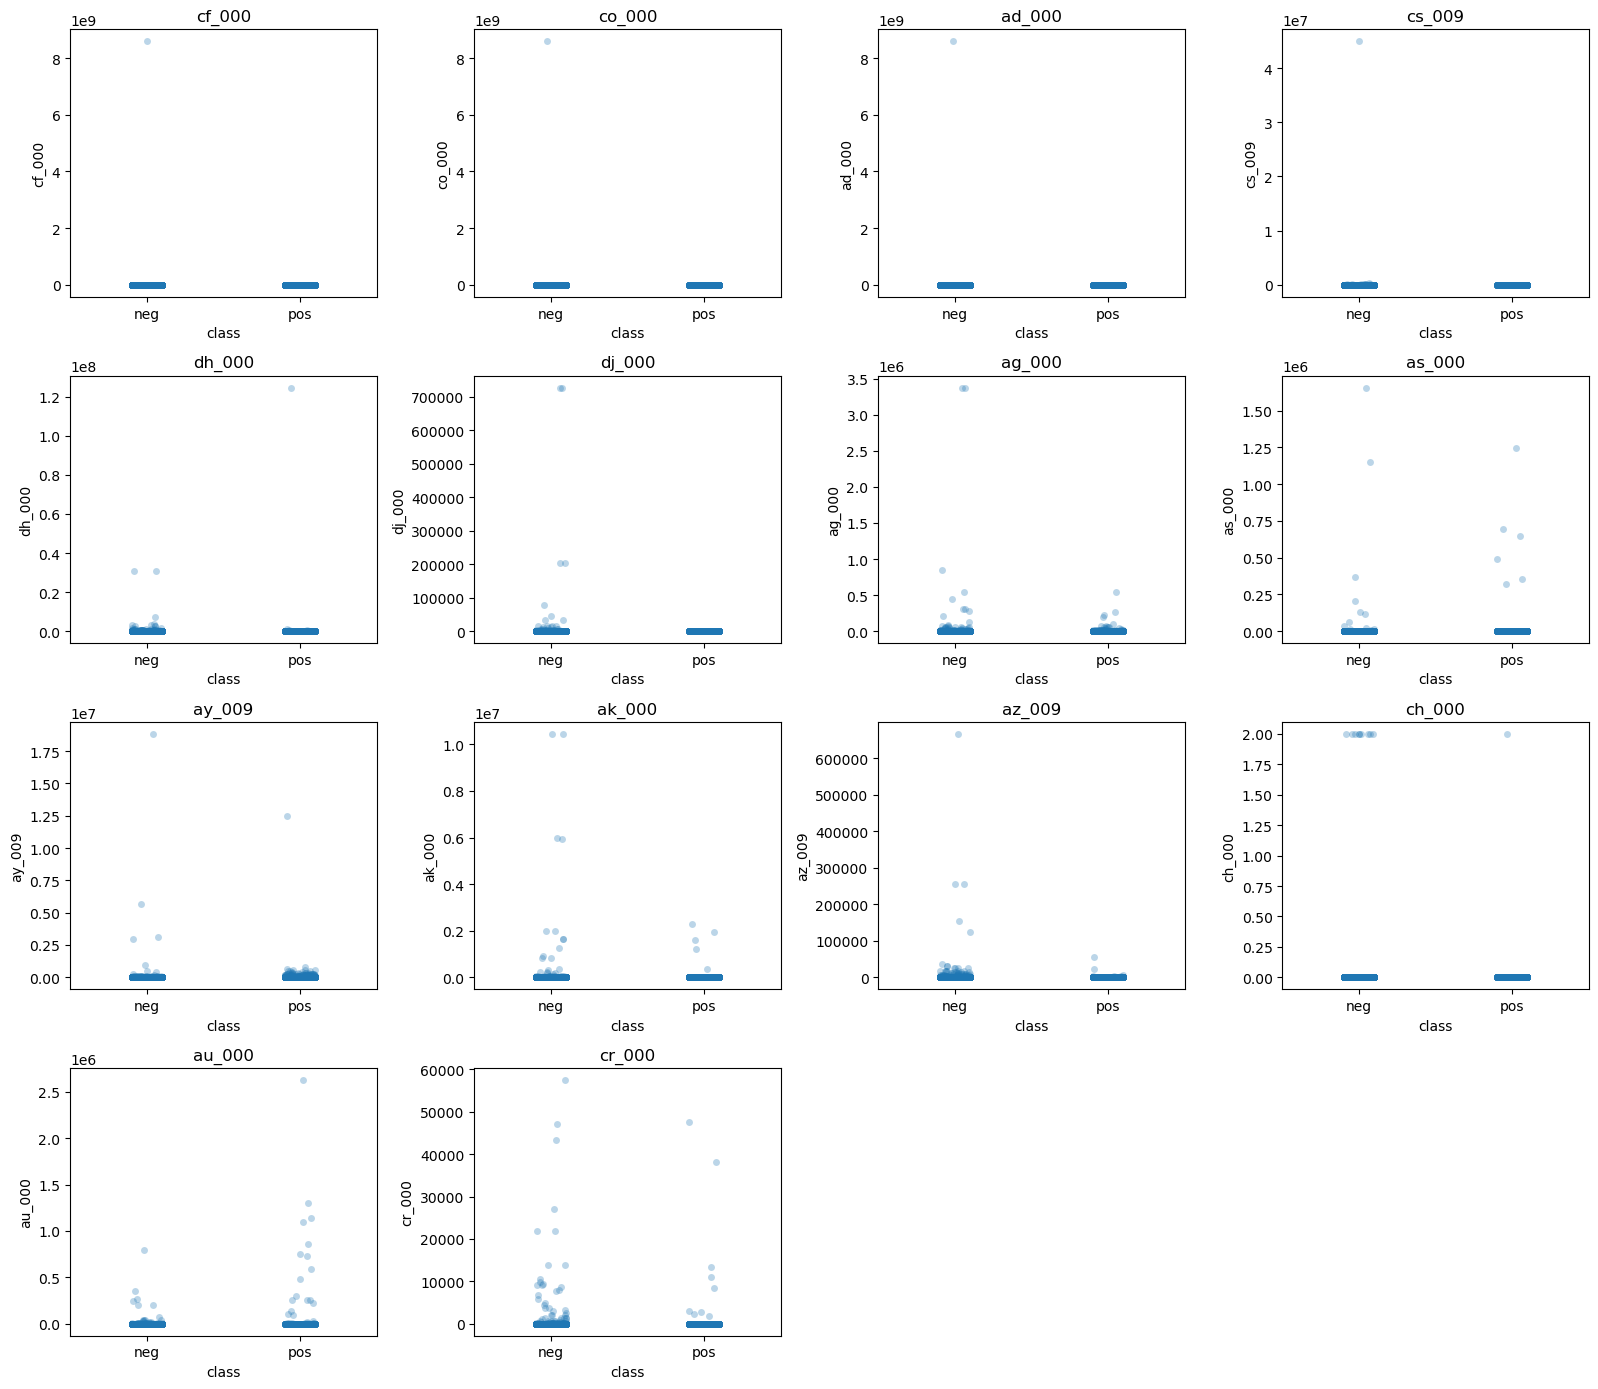

In [27]:
plot_data = X_train_imputed[top_features].copy()
plot_data["class"] = y_train.values
fig, axes = plt.subplots(4, 4, figsize=(16, 14))
axes = axes.flatten()
for i, feature in enumerate(top_features):
    sns.stripplot(
        data=plot_data,
        x="class",
        y=feature,
        ax=axes[i],
        alpha=0.3,
        jitter=True
    )
    axes[i].set_title(feature)
#unused ones
for j in range(len(top_features), len(axes)):
    fig.delaxes(axes[j])
plt.tight_layout()
plt.show()

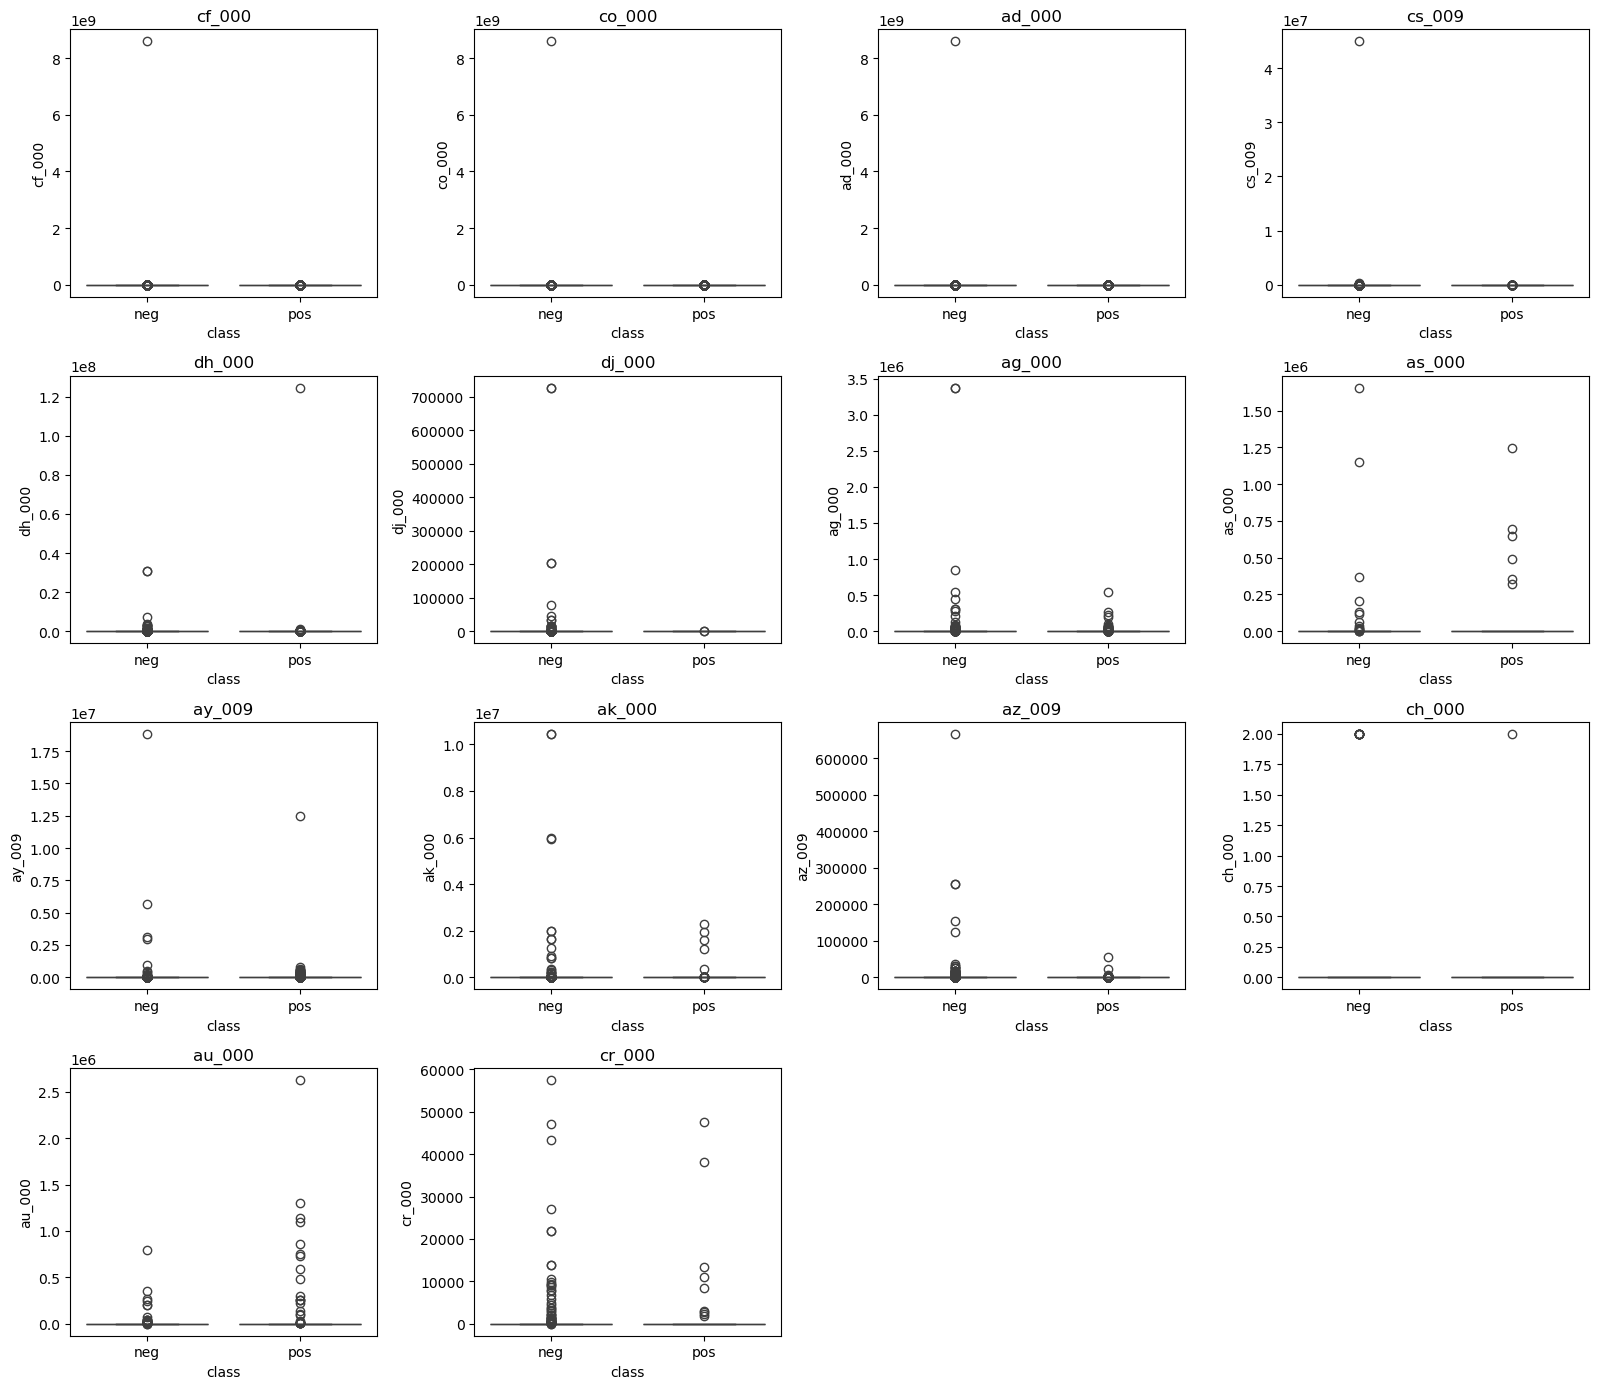

In [28]:
fig, axes = plt.subplots(4, 4, figsize=(16, 14))
axes = axes.flatten()
for i, feature in enumerate(top_features):
    sns.boxplot(
        data=plot_data,
        x="class",
        y=feature,
        ax=axes[i]
    )
    axes[i].set_title(feature)
for j in range(len(top_features), len(axes)):
    fig.delaxes(axes[j])
plt.tight_layout()
plt.show()

The scatter plots help visualize the spread of observations between the two classes. The box plots provide a clearer comparison of the medians, interquartile ranges, and outliers for each feature. No, it is not possible to determine the  statistical significance using scatter plots and box plots alone. Although some features may show noticeable differences between the positive and negative classes, these visualizations do not establish whether the differences are statistically significant and additional statistical testing would be needed.

#### (v) Is this data set imbalanced?

In [29]:
class_counts = y_train.value_counts()
print("Negative observations:", class_counts["neg"])
print("Positive observations:", class_counts["pos"])

Negative observations: 59000
Positive observations: 1000


`Yes, the dataset is imbalanced as there as 59,000 negative observations compared to 1000 positive. As a result, a classification model may become biased toward predicting the negative class and struggle to identify positive cases.

### (c) Train a random forest

training confusion matrix
[[59000     0]
 [    1   999]]

testing confusion martrix
[[15610    15]
 [  106   269]]

misclassification errors
Training Error: 2e-05
Testing Error: 0.00756

AUC
Training AUC: 1.0
Testing AUC: 0.99275


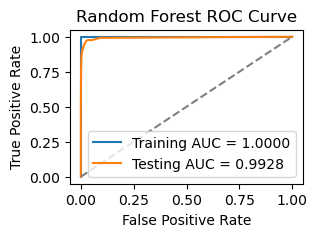


out of bag error
OOB Accuracy: 0.99388
OOB Error: 0.00612

error comparison
Training Error: 2e-05
Testing Error: 0.00756
OOB Error: 0.00612


In [30]:
# Random Forest without compensating for class imbalance
rf = RandomForestClassifier(
    n_estimators=100,
    max_features="sqrt",
    bootstrap=True,
    oob_score=True,
    random_state=42,
    n_jobs=-1
)
rf.fit(X_train_imputed, y_train)
#predict
y_train_pred = rf.predict(X_train_imputed)
y_test_pred = rf.predict(X_test_imputed)
# predict for positive class
y_train_prob = rf.predict_proba(X_train_imputed)[:, 1]
y_test_prob = rf.predict_proba(X_test_imputed)[:, 1]
#labels to binary
y_train_binary = (y_train == "pos").astype(int)
y_test_binary = (y_test == "pos").astype(int)
#confusion matrices
train_cm = confusion_matrix(y_train, y_train_pred, labels=["neg", "pos"])
test_cm = confusion_matrix(y_test, y_test_pred, labels=["neg", "pos"])
print("training confusion matrix")
print(train_cm)
print("\ntesting confusion martrix")
print(test_cm)
#misclassification errors
train_error = 1 - accuracy_score(y_train, y_train_pred)
test_error = 1 - accuracy_score(y_test, y_test_pred)
print("\nmisclassification errors")
print("Training Error:", round(train_error, 5))
print("Testing Error:", round(test_error, 5))
#ROC and AUC
fpr_train, tpr_train, _ = roc_curve(y_train_binary, y_train_prob)
fpr_test, tpr_test, _ = roc_curve(y_test_binary, y_test_prob)
train_auc = roc_auc_score(y_train_binary, y_train_prob)
test_auc = roc_auc_score(y_test_binary, y_test_prob)
print("\nAUC")
print("Training AUC:", round(train_auc, 5))
print("Testing AUC:", round(test_auc, 5))
#plot
plt.figure(figsize=(3, 2))
plt.plot(fpr_train, tpr_train, label=f"Training AUC = {train_auc:.4f}")
plt.plot(fpr_test, tpr_test, label=f"Testing AUC = {test_auc:.4f}")
plt.plot([0, 1], [0, 1], "--", color="gray")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Random Forest ROC Curve")
plt.legend()
plt.show()
# error
oob_error = 1 - rf.oob_score_
print("\nout of bag error")
print("OOB Accuracy:", round(rf.oob_score_, 5))
print("OOB Error:", round(oob_error, 5))
print("\nerror comparison")
print("Training Error:", round(train_error, 5))
print("Testing Error:", round(test_error, 5))
print("OOB Error:", round(oob_error, 5))

### (d) Research class imbalance in random forest

Common approaches to handle class imbalances in a random forest include class weighting, oversampling and undersampling. Class weighting is when the minority class is gven a higher weight so that incorrectly classifying positive observations has a greater impact on the model. Oversampling would be to increase the number of minority-class observations, and undersampling would be to reduce the number of majority-class observations. 

balanced random forest

Training Confusion Matrix:
[[59000     0]
 [    1   999]]

Testing Confusion Matrix:
[[15611    14]
 [  160   215]]

Misclassification Errors:
Training Error: 2e-05
Testing Error: 0.01087

AUC:
Training AUC: 1.0
Testing AUC: 0.99194


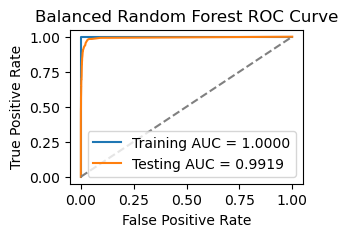


Out-of-Bag Results:
OOB Accuracy: 0.9918
OOB Error: 0.0082

Positive Class Performance:
Training Recall: 0.999
Testing Recall: 0.57333
Testing Precision: 0.93886
Testing F1 Score: 0.71192

comparison of og and balanced random forest
                          Metric  Original Random Forest  Balanced Random Forest
Training Misclassification Error                 0.00002                 0.00002
 Testing Misclassification Error                 0.00756                 0.01087
                    Training AUC                 1.00000                 1.00000
                     Testing AUC                 0.99275                 0.99194
                       OOB Error                 0.00612                 0.00820
         Testing Positive Recall                 0.71733                 0.57333


In [31]:
# Random Forest with Class Imbalance Compensation
#balanced class weights
rf_balanced = RandomForestClassifier(
    n_estimators=100,
    max_features="sqrt",
    bootstrap=True,
    oob_score=True,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)
rf_balanced.fit(X_train_imputed, y_train)
y_train_pred_bal = rf_balanced.predict(X_train_imputed)
y_test_pred_bal = rf_balanced.predict(X_test_imputed)
pos_index = list(rf_balanced.classes_).index("pos")
y_train_prob_bal = rf_balanced.predict_proba(X_train_imputed)[:, pos_index]
y_test_prob_bal = rf_balanced.predict_proba(X_test_imputed)[:, pos_index]
y_train_binary = (y_train == "pos").astype(int)
y_test_binary = (y_test == "pos").astype(int)
#confusion matrices
train_cm_bal = confusion_matrix(y_train, y_train_pred_bal, labels=["neg", "pos"])
test_cm_bal = confusion_matrix(y_test, y_test_pred_bal, labels=["neg", "pos"])
print("balanced random forest")
print("\nTraining Confusion Matrix:")
print(train_cm_bal)
print("\nTesting Confusion Matrix:")
print(test_cm_bal)
#errors
train_error_bal = 1 - accuracy_score(y_train, y_train_pred_bal)
test_error_bal = 1 - accuracy_score(y_test, y_test_pred_bal)
print("\nMisclassification Errors:")
print("Training Error:", round(train_error_bal, 5))
print("Testing Error:", round(test_error_bal, 5))
#ROC and AUC
fpr_train_bal, tpr_train_bal, _ = roc_curve(
    y_train_binary, y_train_prob_bal
)
fpr_test_bal, tpr_test_bal, _ = roc_curve(
    y_test_binary, y_test_prob_bal
)
train_auc_bal = roc_auc_score(y_train_binary, y_train_prob_bal)
test_auc_bal = roc_auc_score(y_test_binary, y_test_prob_bal)
print("\nAUC:")
print("Training AUC:", round(train_auc_bal, 5))
print("Testing AUC:", round(test_auc_bal, 5))
#ROC curves
plt.figure(figsize=(3, 2))
plt.plot(fpr_train_bal, tpr_train_bal,
         label=f"Training AUC = {train_auc_bal:.4f}")
plt.plot(fpr_test_bal, tpr_test_bal,
         label=f"Testing AUC = {test_auc_bal:.4f}")
plt.plot([0, 1], [0, 1], "--", color="gray")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Balanced Random Forest ROC Curve")
plt.legend()
plt.show()
#OOB error
oob_error_bal = 1 - rf_balanced.oob_score_
print("\nOut-of-Bag Results:")
print("OOB Accuracy:", round(rf_balanced.oob_score_, 5))
print("OOB Error:", round(oob_error_bal, 5))
print("\nPositive Class Performance:")
print("Training Recall:", round(
    recall_score(y_train, y_train_pred_bal, pos_label="pos"), 5))
print("Testing Recall:", round(
    recall_score(y_test, y_test_pred_bal, pos_label="pos"), 5))
print("Testing Precision:", round(
    precision_score(y_test, y_test_pred_bal, pos_label="pos"), 5))
print("Testing F1 Score:", round(
    f1_score(y_test, y_test_pred_bal, pos_label="pos"), 5))
original_pos_index = list(rf.classes_).index("pos")
original_train_prob = rf.predict_proba(X_train_imputed)[:, original_pos_index]
original_test_prob = rf.predict_proba(X_test_imputed)[:, original_pos_index]
original_train_pred = rf.predict(X_train_imputed)
original_test_pred = rf.predict(X_test_imputed)
comparison = pd.DataFrame({
    "Metric": [
        "Training Misclassification Error",
        "Testing Misclassification Error",
        "Training AUC",
        "Testing AUC",
        "OOB Error",
        "Testing Positive Recall"
    ],
    "Original Random Forest": [
        1 - accuracy_score(y_train, original_train_pred),
        1 - accuracy_score(y_test, original_test_pred),
        roc_auc_score(y_train_binary, original_train_prob),
        roc_auc_score(y_test_binary, original_test_prob),
        1 - rf.oob_score_,
        recall_score(y_test, original_test_pred, pos_label="pos")
    ],
    "Balanced Random Forest": [
        train_error_bal,
        test_error_bal,
        train_auc_bal,
        test_auc_bal,
        oob_error_bal,
        recall_score(y_test, y_test_pred_bal, pos_label="pos")
    ]
})
print("\ncomparison of og and balanced random forest")
print(comparison.round(5).to_string(index=False))

### (e) XGBoost and Model Trees

Fitting 5 folds for each of 6 candidates, totalling 30 fits
best alpha: 0.001
best cross validation log loss: 0.02118

training confusion matrix
[[58947    53]
 [  222   778]]

testinf confusion matrix
[[15605    20]
 [  118   257]]

training misclassification error: 0.00458
testing misclassifcation error: 0.00862

training auc: 0.99625
testing auc: 0.99539


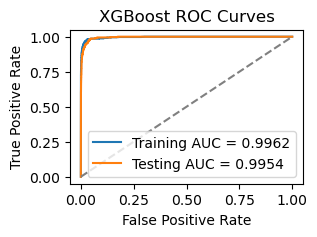


cross validation and test error comparison
5-Fold CV Log Loss: 0.02118
Training Log Loss: 0.01498
Testing Log Loss: 0.02345

cross validation for each alpha


,Alpha,Mean CV Log Loss,Std CV Log Loss
0,0.000,0.021238,0.001789
1,0.001,0.021183,0.001767
2,0.010,0.021326,0.001706
3,0.100,0.021312,0.001762
4,1.000,0.021254,0.001778
5,10.000,0.022726,0.001763


In [32]:
#binary
y_train_binary = (y_train == "pos").astype(int)
y_test_binary = (y_test == "pos").astype(int)
#5 fold
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)
#xg boost
xgb = XGBClassifier(
    objective="binary:logistic",
    eval_metric="logloss",
    n_estimators=100,
    max_depth=3,
    learning_rate=0.1,
    subsample=1.0,
    colsample_bytree=1.0,
    reg_alpha=0,
    random_state=42,
    n_jobs=1
)
#best alpha
param_grid = {
    "reg_alpha": [0, 0.001, 0.01, 0.1, 1, 10]
}
grid_search = GridSearchCV(
    estimator=xgb,
    param_grid=param_grid,
    scoring="neg_log_loss",
    cv=cv,
    n_jobs=-1,
    verbose=1
)
grid_search.fit(X_train_imputed, y_train_binary)
best_model = grid_search.best_estimator_
print("best alpha:", grid_search.best_params_["reg_alpha"])
print("best cross validation log loss:", round(-grid_search.best_score_, 5))
#predict
train_pred = best_model.predict(X_train_imputed)
test_pred = best_model.predict(X_test_imputed)
train_prob = best_model.predict_proba(X_train_imputed)[:, 1]
test_prob = best_model.predict_proba(X_test_imputed)[:, 1]
#confusion matrices
train_cm = confusion_matrix(y_train_binary, train_pred)
test_cm = confusion_matrix(y_test_binary, test_pred)
print("\ntraining confusion matrix")
print(train_cm)
print("\ntestinf confusion matrix")
print(test_cm)
#errors
train_error = 1 - accuracy_score(y_train_binary, train_pred)
test_error = 1 - accuracy_score(y_test_binary, test_pred)
print("\ntraining misclassification error:", round(train_error, 5))
print("testing misclassifcation error:", round(test_error, 5))
#roc and auc
train_fpr, train_tpr, _ = roc_curve(y_train_binary, train_prob)
test_fpr, test_tpr, _ = roc_curve(y_test_binary, test_prob)
train_auc = roc_auc_score(y_train_binary, train_prob)
test_auc = roc_auc_score(y_test_binary, test_prob)
print("\ntraining auc:", round(train_auc, 5))
print("testing auc:", round(test_auc, 5))
#plot
plt.figure(figsize=(3, 2))
plt.plot(
    train_fpr, train_tpr,
    label=f"Training AUC = {train_auc:.4f}"
)
plt.plot(
    test_fpr, test_tpr,
    label=f"Testing AUC = {test_auc:.4f}"
)
plt.plot([0, 1], [0, 1], "--", color="gray")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("XGBoost ROC Curves")
plt.legend()
plt.show()

cv_log_loss = -grid_search.best_score_
train_log_loss = log_loss(y_train_binary, train_prob)
test_log_loss = log_loss(y_test_binary, test_prob)

print("\ncross validation and test error comparison")
print("5-Fold CV Log Loss:", round(cv_log_loss, 5))
print("Training Log Loss:", round(train_log_loss, 5))
print("Testing Log Loss:", round(test_log_loss, 5))
cv_results = pd.DataFrame(grid_search.cv_results_)
alpha_results = pd.DataFrame({
    "Alpha": cv_results["param_reg_alpha"],
    "Mean CV Log Loss": -cv_results["mean_test_score"],
    "Std CV Log Loss": cv_results["std_test_score"]
})
print("\ncross validation for each alpha")
display(alpha_results)

I trained an XGBoost classifier on the APS Failure dataset without compensating for class imbalance. I used L1 regularization through the reg_alpha parameter. To determine the optimal regularization parameter, I performed 5-fold stratified cross-validation and compared several alpha values using log loss.After selecting the optimal alpha, I evaluated the model on both the training and testing datasets. I calculated the confusion matrices, ROC curves, AUC values, and misclassification errors.

### (f) Use SMOTE to pre-process your data

In [33]:
!pip install imbalanced-learn xgboost

Fitting 5 folds for each of 6 candidates, totalling 30 fits
Fitting 5 folds for each of 6 candidates, totalling 30 fits

Original XGBoost
Best Alpha: 0.001

Training Confusion Matrix:
 [[58947    53]
 [  222   778]]

Testing Confusion Matrix:
 [[15605    20]
 [  118   257]]

CV Log Loss: 0.02118
CV Misclassification Error: 0.0072
CV AUC: 0.98857

Training Error: 0.00458
Testing Error: 0.00862
Training AUC: 0.99625
Testing AUC: 0.99539

XGBoost with SMOTE
Best Alpha: 0

Training Confusion Matrix:
 [[57763  1237]
 [   55   945]]

Testing Confusion Matrix:
 [[15307   318]
 [   26   349]]

CV Log Loss: 0.06398
CV Misclassification Error: 0.02268
CV AUC: 0.98441

Training Error: 0.02153
Testing Error: 0.0215
Training AUC: 0.99406
Testing AUC: 0.99314


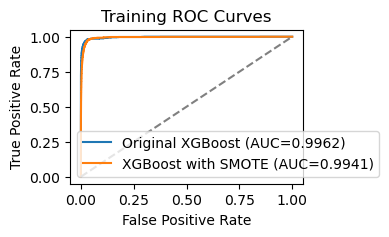

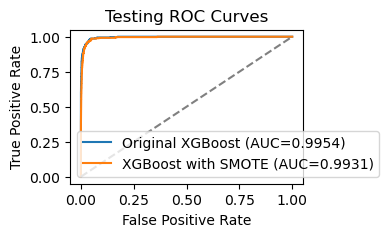


FINAL COMPARISON: ORIGINAL VS. SMOTE


,Best Alpha,CV Log Loss,CV Error,CV AUC,Training Error,Testing Error,Training AUC,Testing AUC
Original XGBoost,0.001,0.021183,0.0072,0.988573,0.004583,0.008625,0.99625,0.995385
XGBoost with SMOTE,0,0.063981,0.022683,0.984406,0.021533,0.0215,0.994064,0.993137



Original XGBoost - Alpha Selection


,Alpha,CV Log Loss,CV Error,CV AUC
0,0.000,0.021238,0.007167,0.988603
1,0.001,0.021183,0.007200,0.988573
2,0.010,0.021326,0.007200,0.988109
3,0.100,0.021312,0.007083,0.988744
4,1.000,0.021254,0.007033,0.987880
5,10.000,0.022726,0.008017,0.988095



XGBoost with SMOTE - Alpha Selection


,Alpha,CV Log Loss,CV Error,CV AUC
0,0.000,0.063981,0.022683,0.984406
1,0.001,0.064084,0.022633,0.984261
2,0.010,0.064093,0.022700,0.984251
3,0.100,0.064487,0.022617,0.984238
4,1.000,0.064009,0.022583,0.984680
5,10.000,0.065197,0.023383,0.984970


In [34]:
y_train_binary = (y_train == "pos").astype(int)
y_test_binary = (y_test == "pos").astype(int)
#5-fold stratified CV
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
#XGBoost model and alpha values
xgb = XGBClassifier(objective="binary:logistic", eval_metric="logloss",
                    n_estimators=100, max_depth=3, learning_rate=0.1,
                    random_state=42, n_jobs=4, tree_method="hist")
param_grid = {"model__reg_alpha": [0, 0.001, 0.01, 0.1, 1, 10]}
scoring = {"log_loss": "neg_log_loss", "accuracy": "accuracy", "auc": "roc_auc"}
#XGBoost
original_pipeline = Pipeline([("model", xgb)])
original_search = GridSearchCV(original_pipeline, param_grid, scoring=scoring,
                               refit="log_loss", cv=cv, n_jobs=1, verbose=1)
original_search.fit(X_train_imputed, y_train_binary)
#XGBoost with SMOTE
smote_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("smote", SMOTE(random_state=42, k_neighbors=5)),
    ("model", xgb)
])
smote_search = GridSearchCV(smote_pipeline, param_grid, scoring=scoring,
                            refit="log_loss", cv=cv, n_jobs=1, verbose=1)
smote_search.fit(X_train_imputed, y_train_binary)
# Evaluate both models
models = {"Original XGBoost": original_search, "XGBoost with SMOTE": smote_search}
results = {}
for name, search in models.items():
    model = search.best_estimator_
    train_pred = model.predict(X_train_imputed)
    test_pred = model.predict(X_test_imputed)
    train_prob = model.predict_proba(X_train_imputed)[:, 1]
    test_prob = model.predict_proba(X_test_imputed)[:, 1]

    train_cm = confusion_matrix(y_train_binary, train_pred)
    test_cm = confusion_matrix(y_test_binary, test_pred)
    train_error = 1 - accuracy_score(y_train_binary, train_pred)
    test_error = 1 - accuracy_score(y_test_binary, test_pred)
    train_fpr, train_tpr, _ = roc_curve(y_train_binary, train_prob)
    test_fpr, test_tpr, _ = roc_curve(y_test_binary, test_prob)
    train_auc = roc_auc_score(y_train_binary, train_prob)
    test_auc = roc_auc_score(y_test_binary, test_prob)
    i = search.best_index_
    cv_log_loss = -search.cv_results_["mean_test_log_loss"][i]
    cv_accuracy = search.cv_results_["mean_test_accuracy"][i]
    cv_auc = search.cv_results_["mean_test_auc"][i]
    cv_error = 1 - cv_accuracy
    results[name] = {
        "Best Alpha": search.best_params_["model__reg_alpha"],
        "CV Log Loss": cv_log_loss, "CV Error": cv_error, "CV AUC": cv_auc,
        "Training Error": train_error, "Testing Error": test_error,
        "Training AUC": train_auc, "Testing AUC": test_auc,
        "Training FPR": train_fpr, "Training TPR": train_tpr,
        "Testing FPR": test_fpr, "Testing TPR": test_tpr
    }
    print("\n" + "=" * 50 + "\n" + name + "\n" + "=" * 50)
    print("Best Alpha:", search.best_params_["model__reg_alpha"])
    print("\nTraining Confusion Matrix:\n", train_cm)
    print("\nTesting Confusion Matrix:\n", test_cm)
    print("\nCV Log Loss:", round(cv_log_loss, 5))
    print("CV Misclassification Error:", round(cv_error, 5))
    print("CV AUC:", round(cv_auc, 5))
    print("\nTraining Error:", round(train_error, 5))
    print("Testing Error:", round(test_error, 5))
    print("Training AUC:", round(train_auc, 5))
    print("Testing AUC:", round(test_auc, 5))
#training ROC curves
plt.figure(figsize=(3, 2))
for name, r in results.items():
    plt.plot(r["Training FPR"], r["Training TPR"],
             label=f'{name} (AUC={r["Training AUC"]:.4f})')
plt.plot([0, 1], [0, 1], "--", color="gray")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Training ROC Curves")
plt.legend()
plt.show()
# Testing ROC curves
plt.figure(figsize=(3, 2))
for name, r in results.items():
    plt.plot(r["Testing FPR"], r["Testing TPR"],
             label=f'{name} (AUC={r["Testing AUC"]:.4f})')
plt.plot([0, 1], [0, 1], "--", color="gray")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Testing ROC Curves")
plt.legend()
plt.show()
# Comparison table
columns = ["Best Alpha", "CV Log Loss", "CV Error", "CV AUC",
           "Training Error", "Testing Error", "Training AUC", "Testing AUC"]
comparison = pd.DataFrame(results).T[columns]
print("\nFINAL COMPARISON: ORIGINAL VS. SMOTE")
display(comparison)
# Compare alpha values
for name, search in models.items():
    cv_table = pd.DataFrame({
        "Alpha": search.cv_results_["param_model__reg_alpha"],
        "CV Log Loss": -search.cv_results_["mean_test_log_loss"],
        "CV Error": 1 - search.cv_results_["mean_test_accuracy"],
        "CV AUC": search.cv_results_["mean_test_auc"]
    })
    print("\n" + name + " - Alpha Selection")
    display(cv_table)

I used SMOTE to create more positive examples and reduce class imbalance. The original XGBoost model had a lower testing error (0.86%) and higher AUC (0.9954). However, SMOTE improved positive-class recall from 68.53% to 93.07%, meaning it detected more actual truck failures. It also increased false positives. Overall, SMOTE was better at detecting failures, while the original model had fewer mistakes overall.

## 2. ISLR 6.6.3

(a) iv. Steadily decrease.
As s increases, the constraint becomes less restrictive, allowing the model to fit the training data better and making the training RSS decrease.
(b) ii. Decrease initially, then eventually start increasing in a U shape.
For the test RSS, the model improves initially, but as it becomes too flexible, it may overfit the training data and increase the value.
(c) iii. Steadily increase.
As the model becomes more flexible, the variance will increase because it becomes more sensitive to changes in the training data.
(d) iv. Steadily decrease.
For the squared bias, as s increases, the model becomes more flexible and can better capture the true relationship, reducing bias.
(e) v. Remain constant.
Irreducible error will remain unchanged, as it is caused by the randomness in the data and cannot be reduced by changing the model.

## 3. ISLR 6.6.5

(a) The Ridge regression optimization problem would be to minimize the equation : (y1 - b1x11 - b2x12)^2 + (y2 - b1x21 - b2x22)^2 + lamda(b1^2 + b2^2)
(b) Since x11 = x12 and x21 = x22, the two variables are identical. Because the two predictors are exactly the same, ridge regression cannot tell them apart and splits the coefficient values equally between the two variables to minimize the penalty, meaning b1 = b2. 
(c) Lasso optimization problem:
Minimize:
(y1 - b1x11 - b2x12)^2 + (y2 - b1x21 - b2x22)^2 + lamda(|b1| + |b2|)
(d) The lasso coefficients are not unique because the two predictors are identical. The RSS depends only on the sum b1 + b2, and the penalty is minimized whenever the coefficients have the same sign and the same sum. In this case b1 + b2 = c, meaning there are infinately many solutions unlike ridge rregression. For example, if c = 3, possible solutions are (b1, b2) = (3, 0),(1, 2), (2, 1), or (0, 3).

## 4. ISLR 8.4.5

1. If using majority vote, the probabilities greater than 0.5 are classified as red. Since there are 6 Red votes and 4 Green votes, the final classification is red.
2. If using the average probability method, we would get (0.1 + 0.15 + 0.2 + 0.2 + 0.55 + 0.6 + 0.6 + 0.65 + 0.7 + 0.75) / 10 = 0.45. Since 0.45 is less than 0.5, the final classification is green.

## 5. ISLR 9.7.3

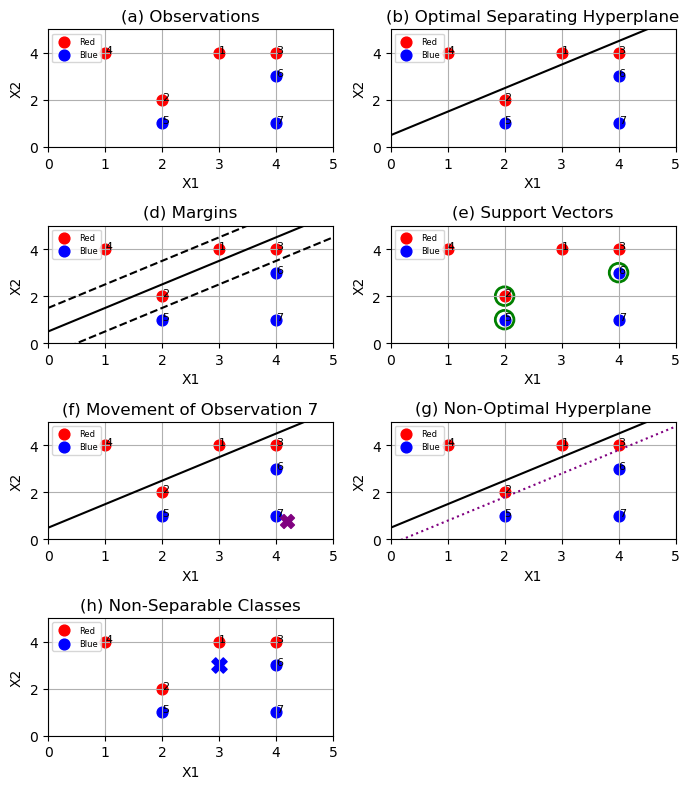

In [35]:
fig, axes = plt.subplots(4, 2, figsize=(7, 8))
axes = axes.flatten()
red = np.array([[3, 4], [2, 2], [4, 4], [1, 4]])
blue = np.array([[2, 1], [4, 3], [4, 1]])
x = np.linspace(0, 5, 100)

def plot_points():
    plt.scatter(red[:, 0], red[:, 1], color='red', label='Red', s=60)
    plt.scatter(blue[:, 0], blue[:, 1], color='blue', label='Blue', s=60)

    for i, p in enumerate(red):
        plt.annotate(i + 1, p, fontsize=8)

    for i, p in enumerate(blue):
        plt.annotate(i + 5, p, fontsize=8)

    plt.xlabel('X1')
    plt.ylabel('X2')
    plt.xlim(0, 5)
    plt.ylim(0, 5)
    plt.grid()
    plt.legend(fontsize=6)
    
# (a) Observations
plt.sca(axes[0])
plot_points()
plt.title('(a) Observations')
# (b) Optimal Separating Hyperplane
plt.sca(axes[1])
plot_points()
plt.plot(x, x + 0.5, 'k-', label='Optimal hyperplane')
plt.title('(b) Optimal Separating Hyperplane')
# (d) Margins
plt.sca(axes[2])
plot_points()
plt.plot(x, x + 0.5, 'k-', label='Hyperplane')
plt.plot(x, x - 0.5, 'k--', label='Margins')
plt.plot(x, x + 1.5, 'k--')
plt.title('(d) Margins')
# (e) Support Vectors
plt.sca(axes[3])
plot_points()
sv = np.array([[2, 2], [2, 1], [4, 3]])
plt.scatter(sv[:, 0], sv[:, 1], s=180, facecolors='none',
            edgecolors='green', linewidths=2, label='Support vectors')
plt.title('(e) Support Vectors')
# (f) Movement of Observation 7
plt.sca(axes[4])
plot_points()
plt.plot(x, x + 0.5, 'k-')
plt.scatter(4.2, 0.8, color='purple', marker='X', s=100,
            label='Moved observation 7')
plt.title('(f) Movement of Observation 7')
# (g) Non-Optimal Hyperplane
plt.sca(axes[5])
plot_points()
plt.plot(x, x + 0.5, 'k-', label='Optimal hyperplane')
plt.plot(x, x - 0.2, 'purple', linestyle=':',
         label='Non-optimal hyperplane')
plt.title('(g) Non-Optimal Hyperplane')
# (h) Non-Separable Classes
plt.sca(axes[6])
plot_points()
plt.scatter(3, 3, color='blue', marker='X', s=120,
            label='Additional blue observation')
plt.title('(h) Non-Separable Classes')
# Remove unused subplot
fig.delaxes(axes[7])
plt.tight_layout()
plt.show()